# Tutorial: G-ORACLE algorithm x PyPSA

In [1]:
import pypsa
import yaml

from mga4all.examples import create_pypsa_network

## 1. Load example PyPSA model

In [2]:
# Load example PyPSA model that the config refers to
n = create_pypsa_network()

INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.4)
INFO:pypsa.network.io:Imported network 'SciGrid-DE' has buses, carriers, generators, lines, loads, storage_units, transformers


In [3]:
# Set the desired solver options
pypsa.options.params.optimize.solver_name = "gurobi"
pypsa.options.params.optimize.solver_options = {
    'Method': 2,  # Use the barrier algorithm
    'Crossover': 0,
}

In [4]:
# Find cost-optimal solution
n.optimize(log_to_console=False);

/tmp/ipykernel_52431/2238090962.py:2: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  n.optimize(log_to_console=False);
INFO:linopy.model: Solve problem using Gurobi solver
INFO:linopy.model:Solver options:
 - Method: 2
 - Crossover: 0
 - log_to_console: False
INFO:linopy.io: Writing time: 0.09s


Set parameter Username


INFO:gurobipy:Set parameter Username


Academic license - for non-commercial use only - expires 2027-09-07


INFO:gurobipy:Academic license - for non-commercial use only - expires 2027-09-07


Read LP format model from file /tmp/linopy-problem-l9y2sz2f.lp


... (7 outputs left out)

Set parameter Crossover to value 0


INFO:gurobipy:Set parameter Crossover to value 0


Set parameter LogToConsole to value 0


INFO:gurobipy:Set parameter LogToConsole to value 0
INFO:gurobipy:Gurobi Optimizer version 12.0.3 build v12.0.3rc0 (linux64 - "Linux Mint 22")
INFO:gurobipy:
INFO:gurobipy:CPU model: Intel(R) Core(TM) i7-10610U CPU @ 1.80GHz, instruction set [SSE2|AVX|AVX2]
INFO:gurobipy:Thread count: 4 physical cores, 8 logical processors, using up to 8 threads
INFO:gurobipy:
INFO:gurobipy:Non-default parameters:
INFO:gurobipy:Method  2
INFO:gurobipy:Crossover  0
INFO:gurobipy:LogToConsole  0
INFO:gurobipy:
INFO:gurobipy:Optimize a model with 688 rows, 296 columns and 1324 nonzeros
INFO:gurobipy:Model fingerprint: 0xd41ae2e6
INFO:gurobipy:Coefficient statistics:
INFO:gurobipy:  Matrix range     [4e-02, 5e+00]
INFO:gurobipy:  Objective range  [4e+02, 2e+03]
INFO:gurobipy:  Bounds range     [0e+00, 0e+00]
INFO:gurobipy:  RHS range        [2e+02, 1e+03]
INFO:gurobipy:Presolve removed 124 rows and 332 columns
INFO:gurobipy:Presolve time: 0.01s
INFO:gurobipy:Presolved: 172 rows, 356 columns, 1572 nonzeros


## 2. Generate alternative solutions with G-ORACLE MGA

### 2.1 Load and check MGA configuration

In [6]:
from mga4all.validate import ORACLEConfig

# Load configuration file
with open("../../configs/test_config_oracle.yaml") as yf:
    test_config = ORACLEConfig.model_validate(yaml.safe_load(yf))

In [7]:
# Check that it reflects the desired setup
test_config

ORACLEConfig(config_name='oracle', model_interface='pypsa', cost_slack=0.2, intensified_technologies=['wind', 'solar', 'gas', 'battery'])

### 2.2 Import algorithm and run

In [8]:
from mga4all.mga_oracle import oracle_algorithm

In [9]:
mga_spatial_alternatives, mga_alternatives = oracle_algorithm(
    config=test_config,
    network_costopt=n,
    delta_convergence=0.08,
    export_nc=False,
)

INFO:linopy.model: Solve problem using Gurobi solver
INFO:linopy.model:Solver options:
 - Method: 2
 - Crossover: 0
 - log_to_console: False


Technologies [] not found in the model


INFO:linopy.io: Writing time: 0.08s


Set parameter Username


INFO:gurobipy:Set parameter Username


Academic license - for non-commercial use only - expires 2027-09-07


... (1,646 outputs left out)

INFO:gurobipy:Barrier solved model in 13 iterations and 0.03 seconds (0.00 work units)


Optimal objective 5.20979096e+00


INFO:gurobipy:Optimal objective 5.20979096e+00


INFO:gurobipy:
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 297 primals, 697 duals
Objective: 5.21e+00
Solver: gurobi
Runtime: 0.03s
Dual bound: 5.21e+00
Solver model: available
Solver message: 2

INFO:pypsa.optimization.optimize:The variable 'oracle_projection_distance' could not be mapped to the network component because it does not include the symbol '-'.
INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-ext-p-lower, Generator-ext-p-upper, Line-ext-s-lower, Line-ext-s-upper, StorageUnit-ext-p_dispatch-lower, StorageUnit-ext-p_dispatch-upper, StorageUnit-ext-p_store-lower, StorageUnit-ext-p_store-upper, StorageUnit-ext-state_of_charge-lower, StorageUnit-ext-state_of_charge-upper, StorageUnit-energy_balance, budget, oracle_upper_battery, oracle_lower_battery, oracle_upper_gas, oracle_lower_gas, oracle_upper_solar, oracle_lower_solar, oracle_upper_wind, oracle_lower_wind were not assigned to the netwo

### 2.3 Inspect the alternatives

<Axes: >

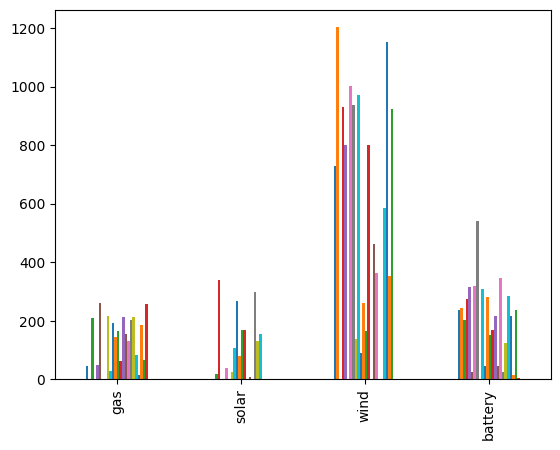

In [27]:
mga_alternatives.plot.bar(legend=None)

<Axes: >

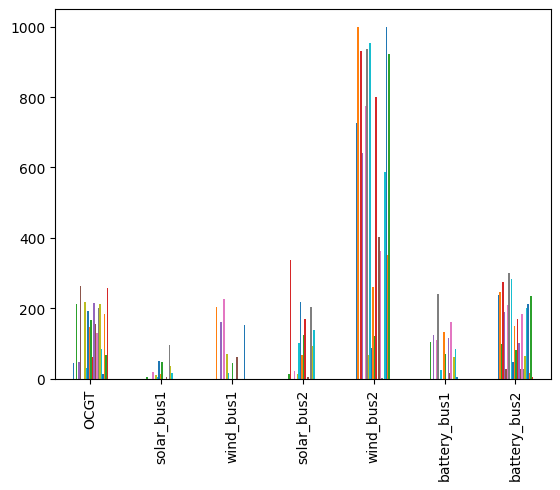

In [28]:
mga_spatial_alternatives.plot.bar(legend=None)

In [12]:
from mga4all.exploration_metrics import exploration_metrics_progression
from mga4all.model_interface_pypsa import extract_capacity_bounds

# Let's first extract the feasibility bounds of the model, needed for the Shannon index.
bounds_spatial, bounds_aggregate = extract_capacity_bounds(n, test_config)

# Then, let's generate diversity metrics with the pre-built functionality
metrics = exploration_metrics_progression(mga_alternatives, lb=bounds_aggregate['lb'], ub=bounds_aggregate['ub'])

Technologies [] not found in the model


<Axes: >

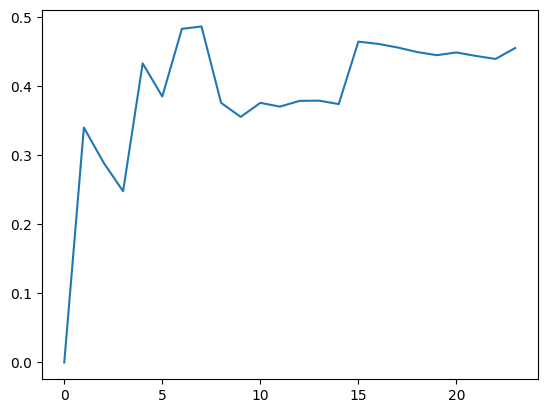

In [13]:
metrics['Shannon'].plot()

<Axes: >

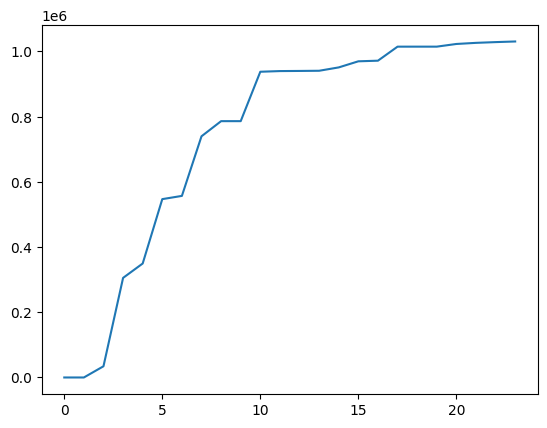

In [14]:
metrics['VESA'].plot()

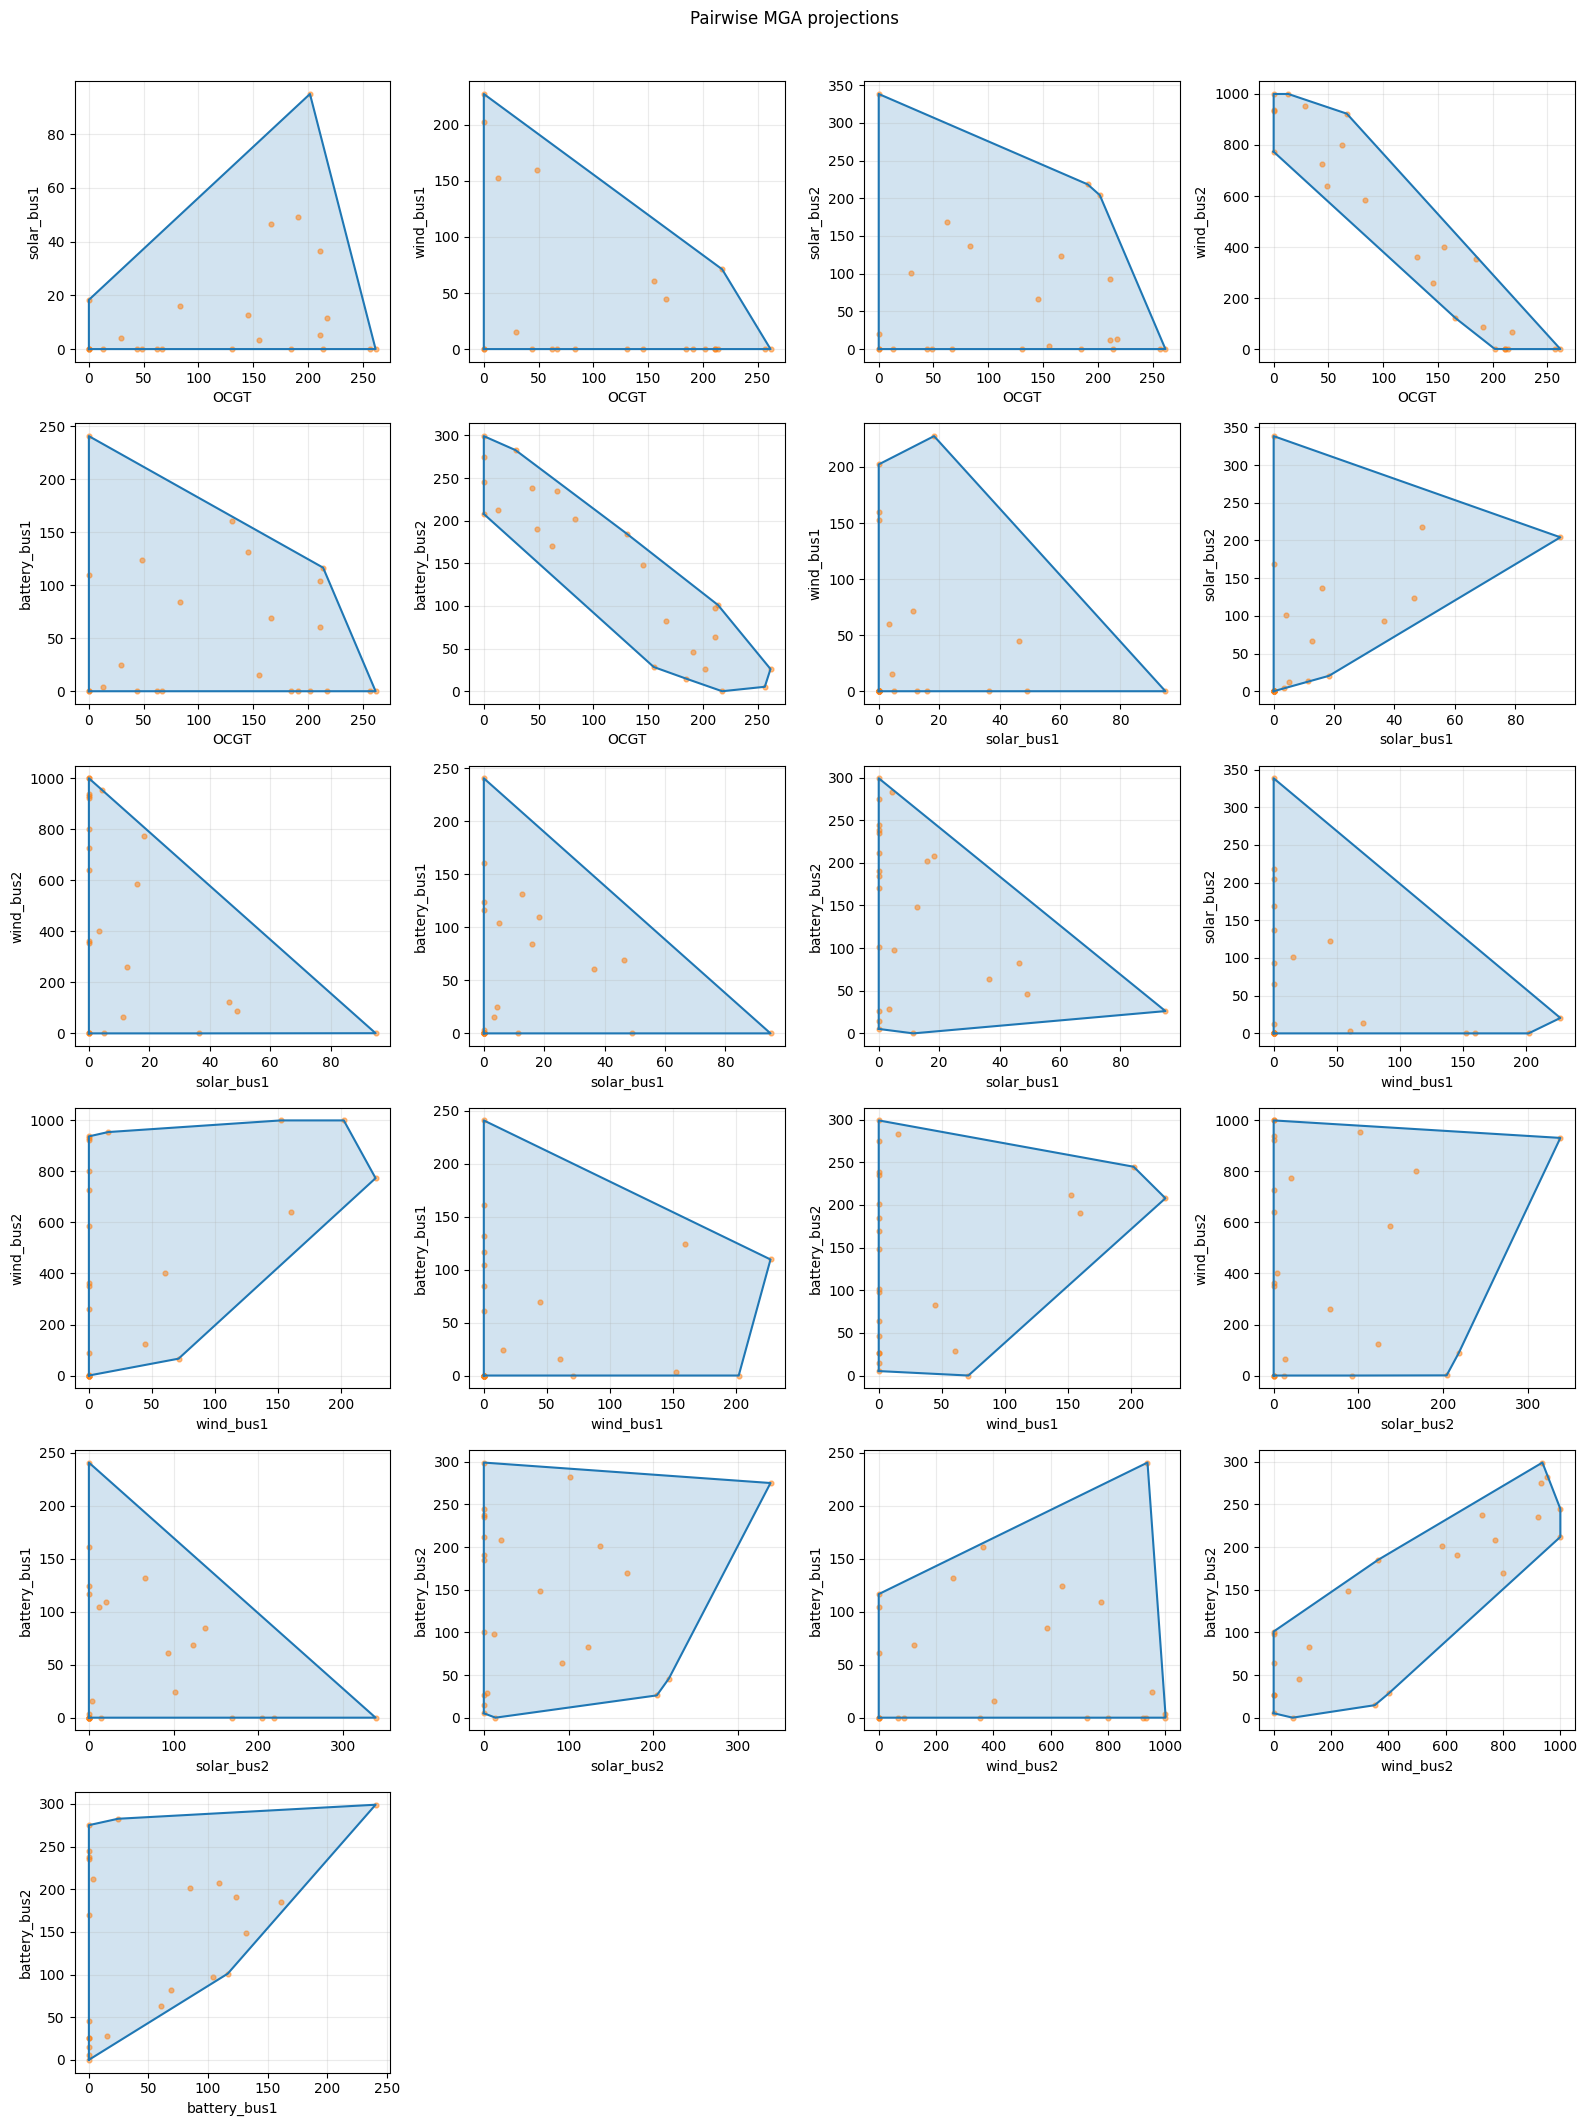

In [15]:
from mga4all.exploration_metrics import plot_vesa_projections

# Let's plot as well the 2D convex hull per spatially-explicit technology pairs
fig, axes = plot_vesa_projections(mga_spatial_alternatives, ncols=4)